# NB 03 · Scénario 2 : Alerte précoce

**Situation :** une cellule de veille surveille **12 chaînes Telegram** de camps opposés pendant toute la guerre en Ukraine (février 2022 à juillet 2023). Cela fait environ 800 messages par jour, en russe et en ukrainien. Personne ne peut tout lire. La question est simple : **« Est-ce qu'il vient de se passer quelque chose d'important ? »**

**Le défi :** l'IA ne reçoit **aucun mot-clé**. On ne lui dit pas « surveille *Kakhovka* » : personne ne savait, la veille, que ce barrage allait sauter. Elle doit trouver toute seule les mots qui **sortent de l'ordinaire**.

**Le parallèle avec God's Eye :** au scénario 2, la disparition d'un *bâtiment* pesait 100 fois plus que celle d'un *navire*. Ici, une rupture reprise par **un seul camp** pèse peu, car ce peut être de la propagande. Une rupture reprise par **les cinq camps à la fois**, médias d'État russes et presse ukrainienne compris, est presque certainement un fait réel.

### La méthode, en trois idées

1. **La ligne de base.** Pour chaque mot et chaque jour, on calcule combien de messages *devraient* le contenir, d'après les 28 jours précédents.
   `attendu = messages du jour × (fréquence du mot sur les 28 derniers jours)`
2. **La rupture.** On mesure l'écart entre l'observé et l'attendu, en tenant compte du hasard. C'est un score « z » : à 3, c'est inhabituel ; à 50, c'est un séisme.
   `z = (observé − attendu) / √(attendu + 1)`
3. **La convergence.** On compte combien de camps différents (sur 5) emploient ce mot ce jour-là.
   **`Score d'alerte = z × (camps / 5)`**

> Pas besoin de réseau de neurones ni de GPU : c'est de la statistique robuste et **explicable**. Un officier peut demander « pourquoi cette alerte ? », et la réponse tient en une ligne. Dans le monde de la défense, c'est souvent plus précieux qu'un point de précision supplémentaire.

In [1]:
import sys
from pathlib import Path

# On retrouve la racine du projet (le dossier qui contient data_lake/) pour importer src/
RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_lake").is_dir())
sys.path.insert(0, str(RACINE / "src"))

import re
import time
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

from spirit_digger.config import OUTPUTS
from spirit_digger.style import ACCENT, ALERTE, FOND, OK, TEXTE, VEILLE, bandeau, theme_ops

theme_ops()
pd.set_option("display.max_colwidth", 110)
bandeau("NB 03 · Alerte précoce", "Théâtre UKRAINE : trouver l'événement sans savoir ce qu'on cherche.", niveau="VEILLE")

corpus = pd.read_parquet(OUTPUTS / "corpus_ukraine.parquet", columns=["date", "source", "camp", "texte"])
corpus["jour"] = corpus["date"].dt.normalize()
CAMPS = sorted(corpus["camp"].unique())
print(f"{len(corpus):,} messages · {corpus['jour'].nunique()} jours · {len(CAMPS)} camps : {', '.join(CAMPS)}")

382,217 messages · 495 jours · 5 camps : International, Russe indépendant (exil), Russie - presse sous contrainte, Russie - État, Ukraine


## 1. Des messages aux « racines »

Le russe se décline : *Пригожин*, *Пригожина*, *Пригожину* désignent la même personne. Sans outil linguistique lourd, on utilise une astuce simple et efficace : **on garde les 6 premières lettres de chaque mot** de 5 lettres ou plus. *Пригожина* devient *пригож*, *Каховской* devient *каховс*.

**Faut-il retirer les mots fréquents** (« заявил », c'est-à-dire « a déclaré ») ? **Non.** Un mot fréquent ne « casse » jamais sa propre ligne de base, donc il ne déclenche pas d'alerte. On ne retire que ce qui crée de **fausses ruptures** :
- les **noms de mois et de jours** (« апреля » explose chaque 1er avril) ;
- les **pieds de message Telegram** (« Подписаться », « Прислать новость »), qu'une chaîne peut ajouter du jour au lendemain.

In [2]:
MOT = re.compile(r"[а-яёіїєґ]{5,}")
FAUSSES_RUPTURES = {
    # mois (au génitif : « 6 июня ») et jours de la semaine
    "января", "феврал", "марта", "апреля", "ноября", "август", "сентяб", "октябр", "декабр",
    "понеде", "вторни", "среду", "четвер", "пятниц", "суббот", "воскре",
    # pieds de message des chaînes
    "подпис", "присла", "новост", "telegr",
}


def racines(texte):
    return {mot[:6] for mot in MOT.findall(texte.lower())} - FAUSSES_RUPTURES


print(racines("Взрыв на Крымском мосту: движение по мосту остановлено. Подписаться"))

{'движен', 'взрыв', 'мосту', 'крымск', 'остано'}


## 2. Comptage : pour chaque jour, chaque racine, chaque camp

Un seul passage sur les 382 000 messages, environ 30 secondes. Pour mémoriser *quels* camps ont employé un mot, on utilise un **masque de bits** : chaque camp est un bit, et `1 << i` vaut 1, 2, 4, 8 ou 16. C'est une technique classique pour stocker un ensemble dans un simple entier.

In [3]:
debut = time.time()
BIT = {camp: 1 << i for i, camp in enumerate(CAMPS)}
compte = defaultdict(Counter)                        # jour -> racine -> nb de messages
masque = defaultdict(lambda: defaultdict(int))       # jour -> racine -> camps (masque de bits)
total = Counter()                                    # jour -> nb total de messages

for jour, camp, texte in zip(corpus["jour"], corpus["camp"], corpus["texte"]):
    total[jour] += 1
    bit = BIT[camp]
    for r in racines(texte):
        compte[jour][r] += 1
        masque[jour][r] |= bit

JOURS = pd.DatetimeIndex(sorted(total))
frequence_globale = Counter()
for jour in JOURS:
    frequence_globale.update(compte[jour])
VOCAB = [r for r, n in frequence_globale.items() if n >= 100]   # racines vues au moins 100 fois
IDX = {r: j for j, r in enumerate(VOCAB)}

# Matrices jours × racines
X = np.zeros((len(JOURS), len(VOCAB)), dtype=np.int32)   # nb de messages
K = np.zeros_like(X)                                     # nb de camps
for i, jour in enumerate(JOURS):
    for r, n in compte[jour].items():
        j = IDX.get(r)
        if j is not None:
            X[i, j] = n
            K[i, j] = bin(masque[jour][r]).count("1")
N = np.array([total[j] for j in JOURS], dtype=float)
print(f"{time.time() - debut:.0f} s · matrice {X.shape[0]} jours × {X.shape[1]:,} racines")

53 s · matrice 495 jours × 9,626 racines


## 3. Calcul du score d'alerte

Tout est vectorisé avec NumPy : 4,8 millions de scores sont calculés en une fraction de seconde. Les **sommes cumulées** donnent le total des 28 jours précédents sans boucle interne.

On ignore les ruptures portées par moins de 15 messages : 3 messages au lieu de 0, c'est spectaculaire en pourcentage, mais ce n'est pas un événement.

In [4]:
FENETRE = 28
MIN_MESSAGES = 15

cumul_x = np.vstack([np.zeros((1, X.shape[1])), np.cumsum(X, axis=0)])
cumul_n = np.concatenate([[0], np.cumsum(N)])

attendu = np.full(X.shape, np.nan)
for i in range(FENETRE, len(JOURS)):
    taux = (cumul_x[i] - cumul_x[i - FENETRE]) / (cumul_n[i] - cumul_n[i - FENETRE])
    attendu[i] = taux * N[i]

z = (X - attendu) / np.sqrt(attendu + 1)
z[(X < MIN_MESSAGES) | np.isnan(z)] = 0
SCORE = z * K / len(CAMPS)

score_du_jour = pd.Series(SCORE.max(axis=1), index=JOURS)
print(f"Les {FENETRE} premiers jours servent de ligne de base : la surveillance commence le {JOURS[FENETRE]:%d/%m/%Y}.")

Les 28 premiers jours servent de ligne de base : la surveillance commence le 24/03/2022.


## 4. Niveaux d'alerte

Il se passe *toujours* quelque chose dans une guerre. On fixe donc des seuils pour que l'alerte reste rare, donc lue :

| Niveau | Score | Fréquence observée |
|---|---|---|
| 🟡 VEILLE | ≥ 20 | environ 2 jours sur 5 |
| 🔴 ALERTE | ≥ 30 | environ 1 jour sur 5 |
| ⚫ ALERTE MAXIMALE | ≥ 60 | environ 1 jour sur 20 |

In [5]:
SEUILS = {"VEILLE": 20, "ALERTE": 30, "ALERTE MAXIMALE": 60}


def niveau(score):
    for nom in ["ALERTE MAXIMALE", "ALERTE", "VEILLE"]:
        if score >= SEUILS[nom]:
            return nom
    return "-"


surveilles = score_du_jour.iloc[FENETRE:]
pd.Series({nom: f"{(surveilles >= s).mean():.0%} des jours ({(surveilles >= s).sum()})" for nom, s in SEUILS.items()},
          name="fréquence")

VEILLE             45% des jours (210)
ALERTE             23% des jours (108)
ALERTE MAXIMALE      6% des jours (29)
Name: fréquence, dtype: str

## 5. Le journal d'alertes

Pour chaque jour d'alerte, Spirit Digger donne :
- **les racines en rupture** (ce qui s'est passé, en quelques mots) ;
- **les camps** qui en parlent ;
- **un message représentatif** : celui du jour qui contient le plus de ces racines.

Le petit **glossaire** traduit les racines les plus fréquentes pour un lecteur francophone. Dans une vraie cellule, c'est le travail du linguiste ; un modèle de traduction pourrait aussi s'en charger.

In [6]:
GLOSSAIRE = {
    "каховс": "Kakhovka", "каховк": "Kakhovka", "затопл": "inondation", "плотин": "barrage", "подтоп": "submersion",
    "дамбы": "digue", "крымск": "de Crimée", "мосту": "pont", "моста": "pont", "керчен": "Kertch", "паромн": "ferry",
    "землет": "séisme", "турции": "Turquie", "сирии": "Syrie", "ейске": "Ieïsk", "самоле": "avion",
    "падени": "chute", "крушен": "crash", "винниц": "Vinnytsia", "прилеп": "Prilepine", "бровар": "Brovary",
    "вертол": "hélicoptère", "еленов": "Olenivka", "пленны": "prisonniers", "новофе": "Novofedorivka",
    "аэродр": "aérodrome", "мобили": "mobilisation", "частич": "partielle", "тайван": "Taïwan", "пелоси": "Pelosi",
    "рефере": "référendum", "ижевск": "Ijevsk", "стрель": "fusillade", "школе": "école", "костро": "Kostroma",
    "брянск": "Briansk", "диверс": "sabotage", "крамат": "Kramatorsk", "вокзал": "gare", "джанко": "Djankoï",
    "вагнер": "Wagner", "ростов": "Rostov", "мятеж": "mutinerie", "пригож": "Prigojine", "кремен": "Krementchouk",
    "крейсе": "croiseur", "москва": "Moskva", "флагма": "navire amiral", "белгор": "Belgorod", "нефтеб": "dépôt pétrolier",
    "татарс": "Tatarsky", "владле": "Vladlen", "стамбу": "Istanbul", "перего": "négociations", "гершко": "Gershkovich",
    "елизав": "Elizabeth", "короле": "reine", "дугино": "Douguina", "дугина": "Douguina", "польше": "Pologne",
    "польши": "Pologne", "ракета": "missile", "херсон": "Kherson", "сурови": "Sourovikine", "днепре": "Dnipro",
    "кремль": "Kremlin", "кремле": "Kremlin", "беспил": "drone", "северн": "Nord (Stream)", "газопр": "gazoduc",
    "зверст": "atrocités", "убийст": "meurtre", "бахмут": "Bakhmout", "артемо": "Artemovsk (Bakhmout)",
    "придне": "Transnistrie", "косово": "Kosovo", "синдзо": "Shinzo (Abe)", "японии": "Japon", "чонгар": "Tchonhar",
    "титан": "Titan (sous-marin)", "батиск": "bathyscaphe", "умани": "Ouman", "новоси": "Novossibirsk",
}


def traduire(liste):
    return ", ".join(f"{r} ({GLOSSAIRE[r]})" if r in GLOSSAIRE else r for r in liste)


def camps_de(i, j):
    return [c for c, b in BIT.items() if masque[JOURS[i]][VOCAB[j]] & b]


alertes = []
for i in np.where(score_du_jour.values >= SEUILS["VEILLE"])[0]:
    s = SCORE[i]
    top = [j for j in np.argsort(-s)[:6] if s[j] >= 0.3 * s.max()]
    alertes.append({
        "jour": JOURS[i], "score": round(float(s.max()), 1), "niveau": niveau(s.max()),
        "racines": [VOCAB[j] for j in top], "camps": len(camps_de(i, top[0])),
    })
alertes = pd.DataFrame(alertes)

# Message représentatif : celui du jour qui contient le plus de racines en rupture
du_jour = corpus[corpus["jour"].isin(alertes["jour"])].groupby("jour")
representatif = {}
for _, a in alertes.iterrows():
    msgs = du_jour.get_group(a.jour)
    nb = msgs["texte"].map(lambda t: len(racines(t) & set(a.racines)))
    meilleur = msgs.loc[nb.idxmax()]
    representatif[a.jour] = f"[{meilleur.source}] {meilleur.texte[:170]}"
alertes["message représentatif"] = alertes["jour"].map(representatif)
alertes["ce qui rompt"] = alertes["racines"].map(traduire)

print(f"{len(alertes)} jours en VEILLE ou plus · top 20 :")
COULEUR_NIVEAU = {"ALERTE MAXIMALE": ALERTE, "ALERTE": VEILLE, "VEILLE": "#9c93c4"}
(alertes.sort_values("score", ascending=False).head(20)
   [["jour", "niveau", "score", "camps", "ce qui rompt", "message représentatif"]]
   .style.format({"jour": lambda d: f"{d:%d/%m/%Y}", "score": "{:.1f}"})
   .map(lambda v: f"color:{COULEUR_NIVEAU.get(v, 'inherit')};font-weight:bold", subset=["niveau"])
   .hide(axis="index"))

210 jours en VEILLE ou plus · top 20 :


jour,niveau,score,camps,ce qui rompt,message représentatif
06/06/2023,ALERTE MAXIMALE,355.2,5,"каховс (Kakhovka), каховк (Kakhovka), затопл (inondation), плотин (barrage)","[УНИАН] Проект ""Радио. Свобода"" ""Схемы"" публикует спутниковые снимки Planet Labs с последствиями разрушений Каховской ГЭС.️Сёла Крынки и Корсунка. Эти два села расположены к юго-"
08/10/2022,ALERTE MAXIMALE,230.3,5,"крымск (de Crimée), мосту (pont)",[RBK] Правительственную комиссию по взрыву на Крымском мосту возглавил вице-премьер Марат Хуснуллин. Премьер-министр Михаил Мишустин по поручению президента создал правительств
06/02/2023,ALERTE MAXIMALE,211.6,5,землет (séisme),"[Ukraine Now] ️Количество погибших в результате землетрясения в Турции возросло до 1498 погибших и 8533 раненых. Сообщается о том, что разрушено 2834 зданий. . Украина Сейчас"
17/10/2022,ALERTE MAXIMALE,167.0,5,ейске (Ieïsk),"[TASS] Огнем после падения самолета в Ейске охвачены четыре этажа многоэтажки, сообщают власти."
14/07/2022,ALERTE MAXIMALE,154.7,5,винниц (Vinnytsia),"[Ukraine Now] Посольство США в Украине просит американцев немедленно покинуть нашу страну. Также гражданам США рекомендуют избегать массовых скоплений людей и публичных мероприятий, та"
06/05/2023,ALERTE MAXIMALE,138.0,5,"прилеп (Prilepine), захара","[Shocked Ukraine] Ответственность за покушение на Захара Прилепина взяло на себя партизанское движение ""Атеш"". .Они охотились за ним с начала этого года..Подписаться"
18/01/2023,ALERTE MAXIMALE,137.7,5,"бровар (Brovary), вертол (hélicoptère)",[RIA News] МВД Украины сообщает о пяти пострадавших в результате падения вертолета рядом с детским садом в Броварах
29/07/2022,ALERTE MAXIMALE,100.2,5,еленов (Olenivka),"[Meduza] США изучают сообщения об ударе по колонии в Еленовке. .Об этом сообщил представитель Совета нацбезопасности США Джон Кирби на брифинге. Он уточнил, что Вашингтон пока не"
09/08/2022,ALERTE MAXIMALE,100.0,5,"новофе (Novofedorivka), аэродр (aérodrome), крыму","[Ukraine Now] В Крыму объявили высокий («желтый») уровень террористической опасности в регионе с 20:00 9 августа до 20:00 24 августа, - росСМИ.Что еще известно на данный момент:.Причин"
21/09/2022,ALERTE MAXIMALE,98.4,5,"мобили (mobilisation), частич (partielle), шойгу","[Shocked Ukraine] Неопубликованный седьмой пункт указа частичной мобилизации на россии касается количества мобилизованных, заявил рот хуйла Песков. По его словам, Кремль не может раскрыть"


## 6. Validation : est-ce que ça marche vraiment ?

Un système d'alerte se juge sur des **faits connus d'avance**. On prend 21 événements majeurs de la période, documentés publiquement. Pour chacun, on note les racines qu'un analyste attendrait. Puis on regarde le niveau atteint par ces racines **le jour même, la veille ou le lendemain** (tolérance de ±1 jour : un événement nocturne est souvent relayé le lendemain).

**Important :** ces racines servent uniquement à *vérifier*. Le système ne les a jamais reçues ; il a trouvé ses alertes tout seul.

In [7]:
REFERENCE = [
    ("2022-04-04", "Massacre de Boutcha révélé", ["зверст", "убийст"]),
    ("2022-04-08", "Frappe sur la gare de Kramatorsk", ["крамат", "вокзал"]),
    ("2022-04-14", "Naufrage du croiseur Moskva", ["крейсе", "флагма"]),
    ("2022-06-27", "Frappe sur le centre commercial de Krementchouk", ["кремен"]),
    ("2022-07-14", "Frappe sur Vinnytsia", ["винниц"]),
    ("2022-07-29", "Explosion à la prison d'Olenivka", ["еленов"]),
    ("2022-08-09", "Explosions sur la base aérienne de Saky (Crimée)", ["новофе", "аэродр"]),
    ("2022-08-21", "Assassinat de Daria Douguina", ["дугино", "дугина"]),
    ("2022-09-21", "Mobilisation partielle en Russie", ["мобили", "частич"]),
    ("2022-09-27", "Sabotage des gazoducs Nord Stream", ["северн", "газопр"]),
    ("2022-10-08", "Explosion du pont de Crimée", ["крымск", "мосту"]),
    ("2022-11-09", "Retrait russe de Kherson", ["херсон", "сурови"]),
    ("2022-11-15", "Missile tombé en Pologne (Przewodów)", ["польше", "польши"]),
    ("2023-01-14", "Frappe sur un immeuble de Dnipro", ["днепре"]),
    ("2023-01-18", "Crash d'hélicoptère à Brovary", ["бровар", "вертол"]),
    ("2023-03-02", "Incursion armée dans l'oblast de Briansk", ["брянск", "диверс"]),
    ("2023-04-02", "Assassinat du blogueur Tatarsky", ["татарс", "владле"]),
    ("2023-05-03", "Drones abattus au-dessus du Kremlin", ["кремль", "кремле", "беспил"]),
    ("2023-05-20", "Prise de Bakhmout revendiquée", ["бахмут", "артемо"]),
    ("2023-06-06", "Destruction du barrage de Kakhovka", ["каховс", "плотин"]),
    ("2023-06-23", "Mutinerie du groupe Wagner", ["пригож", "вагнер", "мятеж"]),
]

lignes = []
for date, evenement, attendues in REFERENCE:
    i = JOURS.get_loc(pd.Timestamp(date))
    fenetre = range(max(i - 1, 0), min(i + 2, len(JOURS)))
    meilleur, jour_meilleur = 0.0, None
    for k in fenetre:
        for r in attendues:
            if r in IDX and SCORE[k, IDX[r]] > meilleur:
                meilleur, jour_meilleur = float(SCORE[k, IDX[r]]), JOURS[k]
    lignes.append({"date": pd.Timestamp(date), "événement": evenement, "score": round(meilleur, 1),
                   "niveau atteint": niveau(meilleur),
                   "décalage (j)": (jour_meilleur - pd.Timestamp(date)).days if jour_meilleur is not None else None})
validation = pd.DataFrame(lignes)

detectes = (validation["score"] >= SEUILS["ALERTE"]).sum()
veille = ((validation["score"] >= SEUILS["VEILLE"]) & (validation["score"] < SEUILS["ALERTE"])).sum()
print(f"Niveau ALERTE ou plus : {detectes}/{len(validation)} événements · en VEILLE seulement : {veille} · "
      f"manqués : {len(validation) - detectes - veille}")
(validation.style.format({"date": lambda d: f"{d:%d/%m/%Y}", "score": "{:.1f}", "décalage (j)": "{:+.0f}"})
   .map(lambda v: f"color:{COULEUR_NIVEAU.get(v, ALERTE if v == '-' else 'inherit')};font-weight:bold",
        subset=["niveau atteint"])
   .hide(axis="index"))

Niveau ALERTE ou plus : 17/21 événements · en VEILLE seulement : 2 · manqués : 2


date,événement,score,niveau atteint,décalage (j)
04/04/2022,Massacre de Boutcha révélé,16.7,-,+0
08/04/2022,Frappe sur la gare de Kramatorsk,80.9,ALERTE MAXIMALE,+0
14/04/2022,Naufrage du croiseur Moskva,73.8,ALERTE MAXIMALE,+0
27/06/2022,Frappe sur le centre commercial de Krementchouk,74.9,ALERTE MAXIMALE,+0
14/07/2022,Frappe sur Vinnytsia,154.7,ALERTE MAXIMALE,+0
29/07/2022,Explosion à la prison d'Olenivka,100.2,ALERTE MAXIMALE,+0
09/08/2022,Explosions sur la base aérienne de Saky (Crimée),100.0,ALERTE MAXIMALE,+0
21/08/2022,Assassinat de Daria Douguina,53.9,ALERTE,+1
21/09/2022,Mobilisation partielle en Russie,98.4,ALERTE MAXIMALE,+0
27/09/2022,Sabotage des gazoducs Nord Stream,22.9,VEILLE,+0


## 7. Vue d'ensemble : 16 mois de guerre sur un seul graphique

Chaque barre est le score d'alerte maximal du jour. Les numéros marquent les événements de référence.

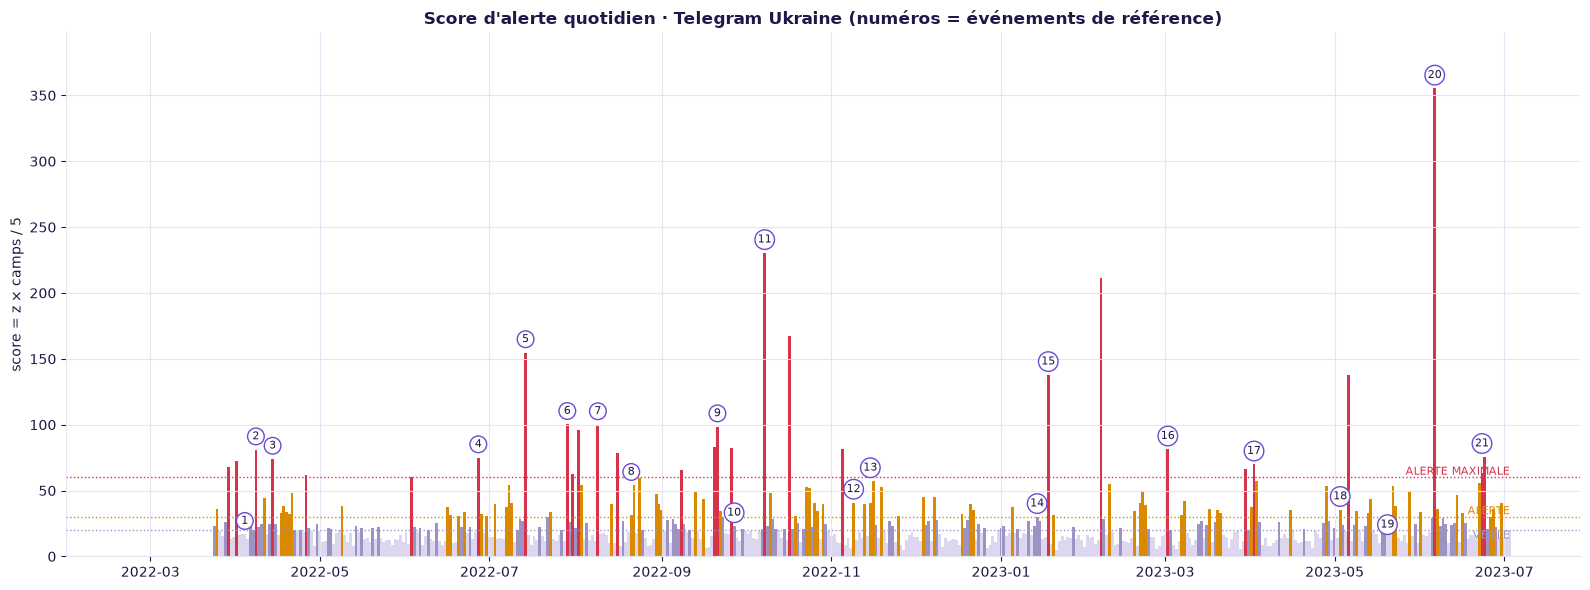

1. Massacre de Boutcha révélé  2. Frappe sur la gare de Kramatorsk  3. Naufrage du croiseur Moskva  4. Frappe sur le centre commercial de Krementchouk  5. Frappe sur Vinnytsia  6. Explosion à la prison d'Olenivka  7. Explosions sur la base aérienne de Saky (Crimée)  8. Assassinat de Daria Douguina  9. Mobilisation partielle en Russie  10. Sabotage des gazoducs Nord Stream  11. Explosion du pont de Crimée  12. Retrait russe de Kherson  13. Missile tombé en Pologne (Przewodów)  14. Frappe sur un immeuble de Dnipro  15. Crash d'hélicoptère à Brovary  16. Incursion armée dans l'oblast de Briansk  17. Assassinat du blogueur Tatarsky  18. Drones abattus au-dessus du Kremlin  19. Prise de Bakhmout revendiquée  20. Destruction du barrage de Kakhovka  21. Mutinerie du groupe Wagner


In [8]:
fig, ax = plt.subplots(figsize=(16, 6))
couleurs = [ALERTE if s >= SEUILS["ALERTE MAXIMALE"] else VEILLE if s >= SEUILS["ALERTE"] else
            "#9c93c4" if s >= SEUILS["VEILLE"] else "#dcd6ee" for s in score_du_jour.values]
ax.bar(score_du_jour.index, score_du_jour.values, width=1.0, color=couleurs)
for nom, s in SEUILS.items():
    ax.axhline(s, ls=":", lw=1, color=COULEUR_NIVEAU[nom])
    ax.text(score_du_jour.index[-1], s, f" {nom}", va="top" if nom == "VEILLE" else "bottom", ha="right",
            fontsize=8, color=COULEUR_NIVEAU[nom])

for n, ligne in enumerate(validation.itertuples(), start=1):
    y = max(ligne.score, 8) + 8
    ax.annotate(str(n), (ligne.date, y), ha="center", fontsize=8, color=TEXTE,
                bbox=dict(boxstyle="circle,pad=0.25", fc=FOND, ec=ACCENT, lw=1))
ax.set_ylim(0, score_du_jour.max() * 1.12)
ax.set_title("Score d'alerte quotidien · Telegram Ukraine (numéros = événements de référence)")
ax.set_ylabel("score = z × camps / 5")
plt.tight_layout()
plt.savefig(OUTPUTS / "03_chronologie_alertes.png", dpi=130)
plt.show()

print("  ".join(f"{n}. {e}" for n, e in enumerate(validation["événement"], start=1)))

## 8. Zoom : juin 2023, deux crises en trois semaines

On suit le score de trois racines, jour après jour.

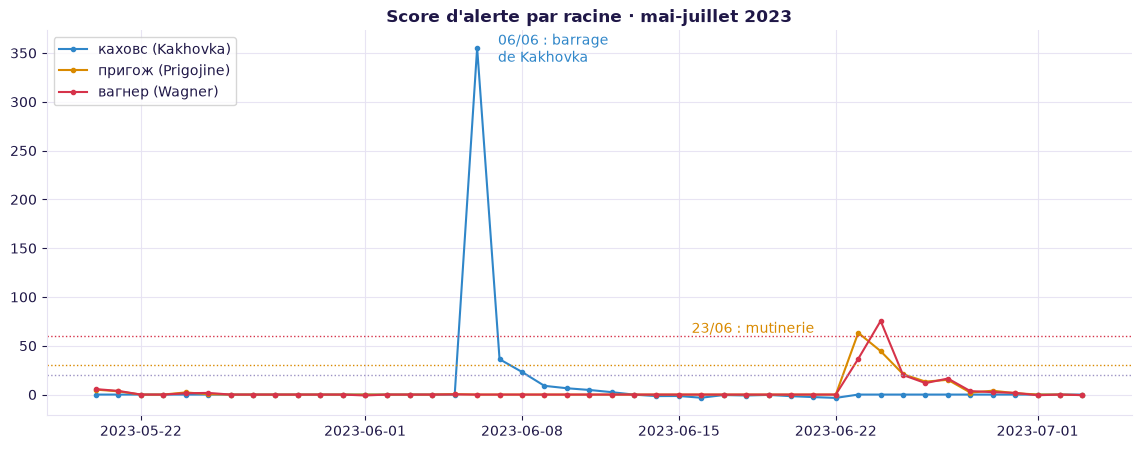

In [9]:
zoom = (JOURS >= "2023-05-20")
fig, ax = plt.subplots(figsize=(14, 5))
for r, couleur, nom in [("каховс", "#2f86c9", "Kakhovka"), ("пригож", VEILLE, "Prigojine"), ("вагнер", ALERTE, "Wagner")]:
    ax.plot(JOURS[zoom], SCORE[zoom, IDX[r]], marker="o", ms=3, color=couleur, label=f"{r} ({nom})")
for nom, s in SEUILS.items():
    ax.axhline(s, ls=":", lw=1, color=COULEUR_NIVEAU[nom])
ax.annotate("06/06 : barrage\nde Kakhovka", (pd.Timestamp("2023-06-06"), SCORE[JOURS.get_loc("2023-06-06"), IDX["каховс"]]),
            xytext=(15, -10), textcoords="offset points", color="#2f86c9")
ax.annotate("23/06 : mutinerie", (pd.Timestamp("2023-06-23"), SCORE[JOURS.get_loc("2023-06-23"), IDX["пригож"]]),
            xytext=(-120, 0), textcoords="offset points", color=VEILLE)
ax.set_title("Score d'alerte par racine · mai-juillet 2023")
ax.legend(loc="upper left")
plt.show()

**Lecture honnête :** Spirit Digger détecte la mutinerie **le jour même**, avec les 5 camps, mais il ne la **prédit** pas. Prigojine faisait déjà la une depuis des mois (Bakhmout, ses vidéos contre l'état-major), sa ligne de base était donc élevée, et ses déclarations de début juin ne ressortent pas. L'alerte précoce porte sur la **détection rapide**, pas sur la divination. Avec des messages horodatés à la minute plutôt qu'au jour, le délai de détection se compterait en dizaines de minutes.

## 9. Signaux mono-camp : bruit éditorial ou vrai sujet ?

Notre score pénalise les ruptures portées par un seul camp. Mais un analyste ne les jette pas : il les **examine à part**. Une forte rupture dans **un seul camp** peut être :
- un **changement éditorial** : une chaîne modifie son pied de message, et le mot apparaît soudain dans *tous* ses messages ;
- une **campagne coordonnée** : le même narratif poussé partout en même temps ;
- un **sujet que l'autre camp ignore** : une affaire intérieure, ou une exclusivité.

Diagnostic automatique : c'est une signature éditoriale, pas une information, si le mot apparaît dans **plus de la moitié des messages d'une même chaîne** ce jour-là, **ou** s'il se trouve presque toujours **dans les 100 derniers caractères** du message (là où sont les pieds de message).

In [10]:
mono = []
for i, j in zip(*np.where((z >= 15) & (K <= 1) & (X >= 30))):
    jour, r = JOURS[i], VOCAB[j]
    msgs = corpus[corpus["jour"] == jour]
    contient = msgs["texte"].map(lambda t: r in racines(t))
    chaine = msgs.loc[contient, "source"].value_counts().index[0]
    part = contient[msgs["source"] == chaine].mean()            # part des messages de la chaîne contenant le mot
    en_fin = msgs.loc[contient, "texte"].map(lambda t: r in t.lower()[-100:]).mean()   # mot placé en fin de message ?
    exemple = msgs.loc[contient & (msgs["source"] == chaine), "texte"].iloc[0]
    pos = exemple.lower().find(r)
    mono.append({"jour": jour, "racine": traduire([r]), "messages": int(X[i, j]), "z": round(float(z[i, j]), 1),
                 "chaîne": chaine, "part des messages de la chaîne": part, "en fin de message": en_fin,
                 "diagnostic": "pied de message (éditorial)" if part > 0.5 or en_fin > 0.7 else "sujet mono-camp",
                 "extrait": "…" + exemple[max(0, pos - 60):pos + 70] + "…"})
mono = pd.DataFrame(mono).sort_values("z", ascending=False).drop_duplicates(["racine", "chaîne", "diagnostic"])
print(f"{len(mono)} ruptures mono-camp distinctes :")
(mono.style.format({"jour": lambda d: f"{d:%d/%m/%Y}", "z": "{:.1f}", "part des messages de la chaîne": "{:.0%}",
                    "en fin de message": "{:.0%}"})
     .map(lambda v: f"color:{VEILLE if v.startswith('pied') else OK};font-weight:bold", subset=["diagnostic"])
     .hide(axis="index"))

6 ruptures mono-camp distinctes :


jour,racine,messages,z,chaîne,part des messages de la chaîne,en fin de message,diagnostic,extrait
13/02/2023,униан,66,45.0,УНИАН,94%,100%,pied de message (éditorial),"… роты, воевал на Донецком направлении. Подписаться на канал УНИАН…"
09/03/2023,восхит,44,41.7,УНИАН,40%,100%,pied de message (éditorial),"…я другой авторитарный режим"". .Остаться с нами в Телеграм | Восхититься нашим YouTube…"
10/03/2023,остать,61,31.5,УНИАН,88%,100%,pied de message (éditorial),"…рмации, так как ситуация в энергосистеме остается сложной. .Остаться с нами в Телеграм | Восхититься нашим YouTube…"
01/04/2023,мерсед,36,29.7,Ukraine Now,34%,28%,sujet mono-camp,…После получения подозрения Паша Мерседес быстро покидает Лавру. Так спешили уехать подальше от сотрудн…
12/03/2023,нашим,55,21.4,УНИАН,100%,98%,pied de message (éditorial),… видели его лично .Остаться с нами в Телеграм | Восхититься нашим YouTube…
18/02/2023,канал,71,15.4,УНИАН,95%,99%,pied de message (éditorial),…ти никаких ограничений электроснабжения нет. Подписаться на канал УНИАН…


**Lecture analyste :** la plupart des ruptures mono-camp sont du **bruit éditorial**, ici les nouveaux pieds de message d'UNIAN (« Остаться с нами в Телеграм | Восхититься нашим YouTube »). Sans la pondération par les camps, Spirit Digger aurait levé de fausses alertes. Les autres sont de **vrais sujets** que seul un camp couvre, comme l'affaire du métropolite surnommé « Pacha Mercedes », poursuivi par le SBU : une affaire intérieure ukrainienne que la presse russe ignore. **C'est exactement ce que le NB 05 creusera : qui parle de quoi, et qui se tait.**

## 10. Sauvegarde pour le bulletin (NB 06)

In [11]:
sortie = alertes.drop(columns=["racines"]).assign(racines=alertes["racines"].map(", ".join))
sortie.to_csv(OUTPUTS / "alertes_ukraine.csv", index=False)
validation.to_csv(OUTPUTS / "validation_alertes.csv", index=False)
print(f"{len(sortie)} alertes → alertes_ukraine.csv · validation → validation_alertes.csv")

210 alertes → alertes_ukraine.csv · validation → validation_alertes.csv


## Ce qu'il faut retenir

- **Sans aucun mot-clé**, Spirit Digger lève une ALERTE sur **17 des 21 événements de référence**, le jour même ou le lendemain. Il fait aussi ressortir des événements hors du conflit (séisme en Turquie, mort d'Elizabeth II) : il détecte **l'inattendu**, quel qu'il soit.
- **La convergence des camps** est le cœur de la fiabilité : une info que TASS *et* les chaînes ukrainiennes reprennent le même jour est un fait. Une rupture dans un seul camp est un sujet d'enquête.
- **Limites, à dire en démo :**
  - les événements **graduels** comme la chute de Bakhmout ne créent pas de rupture ;
  - un événement peut en **éclipser** un autre (Nord Stream face à la fusillade d'Ijevsk) ;
  - la troncature à 6 lettres est rudimentaire ;
  - le système **détecte**, il ne **prédit** pas.

> **Phrase de démo :** « Sans qu'on lui dise quoi chercher, Spirit Digger a lu 382 000 messages en russe et en ukrainien. En 40 secondes, il a levé l'alerte sur la destruction du barrage de Kakhovka et sur la mutinerie Wagner, chaque fois confirmées par cinq camps qui se contredisent sur tout le reste. »

**Prochaine étape → NB 04 : graphe de relations.**